# PHATPSY Python Driver: Interactive Workflow & 3D Visualization

The **PHATPSY** (Projected Hamiltonian Approach to Polyatomic Systems) package performs non-empirical self-consistent field (SCF) calculations on molecular and chemisorption systems using localized pseudopotentials and projected core/valence basis sets.

This interactive Jupyter Notebook demonstrates:
1. **Dual Input Support**: Loading and inspecting calculations from **either** modern **YAML** or legacy **Namelist / `.stdin`** decks.
2. **Two-Way Conversion**: Converting legacy punch-card formatted decks to structured YAML and vice versa.
3. **End-to-End Execution**: Running calculations through the high-level `PhatpsyDriver` API with automatic format detection.
4. **Cycle-by-Cycle Step-Through**: Stepping through the internal Fortran/C-bridge phases:
   - Common block and state initialization
   - Deck parsing (`&CTLINP`) and title processing
   - Dynamic workspace sizing and array allocation
   - Element basis loading and 0th-order atomic GCHF calculations
   - Polyatomic self-consistent loop cycle-by-cycle convergence
5. **JSON Export & Schema Inspection**: Exporting full quantum observables to JSON.
6. **Data Visualization**:
   - Total energy decomposition and virial ratio check ($-V/T$)
   - Molecular orbital eigenvalue spectrum with HOMO/LUMO identification
   - Unpacking symmetric packed matrices (`overlap_packed` $S_{ij}$) and heatmap plotting
   - Molecular orbital coefficient matrix ($C_{\mu i}$) visualization
7. **Localized Valence-Bond (LVB) Alternating-Spin Theory**:
   - Explicit `spin="up"` / `spin="down"` declarations
   - Automated alternating-spin assignment (Néel / LVB bipartite graph solver)
   - Decoupled electron pairs with zero net molecular spin
8. **Special Atomic Centers & Symmetry Operations**:
   - Virtual / ghost basis centers (`virtual=True`, `QVIRTL=T`) for local coordination neighborhood completion
   - Fixed / frozen atoms (`fixed=True`, `QFIXED=T`)
   - Point-group symmetry operations (`ISYM`, `IXYZ`, `NEQAT`)
9. **Interactive 3D WebGL Visualization**:
   - Embedded Three.js 3D viewer directly inside Jupyter via `deck.show()`
   - Color-coded spin vectors ($\uparrow$ / $\downarrow$), ghost shells, fixed cages, and symmetry planes!
10. **State Checkpointing & Warm Geometry Restarts**:
   - Full serialization of calculation state (`CalculationState`) to JSON and compressed NumPy (`.npz`)
   - Seeding perturbed geometries with converged wavefunctions
11. **Transferable Embedded Atomic States**:
   - Localized `EmbeddedAtomState` extraction, orbital charges, and substrate reusability
12. **Internal Coordinates & Wilson B-Matrix (`phatpsy.coords`)**:
   - Automatic bond, angle, and dihedral identification from covalent radii
   - Wilson B-matrix derivative calculation ($B_{ki} = \partial q_k / \partial x_i$)
   - Canonical Z-matrix generation and exact Cartesian NeRF reconstruction
13. **Automated 1D & 2D Potential Energy Surface (PES) Mapping (`phatpsy.pes`)**:
   - Automated 1D coordinate scans with warm-restarts, virial ratio checking, and parabolic minimum fit
   - Automated 2D grid scans and contour surface maps
14. **Ground-State Geometry Optimization (`phatpsy.optimize`)**:
   - BFGS quasi-Newton structure relaxation with trust-region step clamping and Armijo line search
15. **Pure Modern Fortran 2018 Kernels (`_phatpsy_core`)**:
   - 100% pure Fortran 2018 core with direct Python access to `linalg`, `density`, `modelpot`, `symmetry`, and `diagnostics` modules.

In [1]:
import sys
import os
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

# Locate repository root and configure sys.path
REPO_ROOT = Path("..").resolve() if Path("..").joinpath("phatpsy").exists() else Path(".").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from phatpsy import (
    PhatpsyDriver,
    CalculationDeck,
    ControlConfig,
    AtomConfig,
    SymmetrySpec,
    build_molecule,
    build_diatomic,
    parse_stdin_file,
    parse_stdin_to_deck,
    save_results_to_json,
    unpack_symmetric,
    DIISAccelerator,
    get_element_basis,
    list_available_elements,
    assign_alternating_spin,
    visualize_deck,
    show_deck,
)
import _phatpsy_core as core

print(f"Repository Root: {REPO_ROOT}")
print("Core Fortran Extension (_phatpsy_core): Loaded successfully.")
print(f"Available Basis Elements: {len(list_available_elements())} elements in library.")

Repository Root: /Users/jacksmith/phatpsy2
Core Fortran Extension (_phatpsy_core): Loaded successfully.
Available Basis Elements: 103 elements in library.


## Step 1: Input Format Selection (YAML vs. Legacy Namelist)
PHATPSY supports two input formats:
- **Modern YAML (`.yaml` / `.yml`)**: Clean, human-readable format with explicit spin, virtual, and fixed attributes.
- **Legacy Namelist (`.stdin`)**: Traditional Fortran hybrid deck containing 80-column title cards, `&CTLINP` namelists, and fixed-format punch-card STO tables.

Below, you can select which format to load by setting `input_format = "yaml"` or `"stdin"`. Both are parsed into a unified `CalculationDeck` Python object.

In [2]:
# Choose input format to load: 'yaml' or 'stdin'
input_format = "yaml"  # Switch between "yaml" and "stdin"

if input_format.lower() == "yaml":
    input_deck_path = REPO_ROOT / "examples" / "n2.yaml"
    deck = CalculationDeck.from_yaml(input_deck_path)
    print(f"Successfully loaded YAML deck from: {input_deck_path}")
else:
    input_deck_path = REPO_ROOT / "examples" / "n2.stdin"
    deck = parse_stdin_to_deck(input_deck_path)
    print(f"Successfully parsed legacy .stdin deck from: {input_deck_path}")

print(f"\nTitle: '{deck.title}'")
print("\n--- Control Configuration ---")
for k, v in deck.control.to_dict().items():
    print(f"  {k:26s} : {v}")

print("\n--- Molecular Geometry ---")
for idx, atom in enumerate(deck.geometry, 1):
    sym_info = f" (Symmetry: {atom.symmetry.to_dict()})" if atom.symmetry else ""
    spin_info = f" [Spin: {atom.spin}]" if atom.spin else ""
    print(f"  Atom {idx}: {atom.element} at {atom.xyz}{spin_info}{sym_info}")

Successfully loaded YAML deck from: /Users/jacksmith/phatpsy2/examples/n2.yaml

Title: ''

--- Control Configuration ---
  spin_unrestricted          : True
  max_cycles                 : 100
  convergence                : 0.0001
  time_limit                 : 360.0
  charge_damp                : 0.5
  charge_accel               : 1.0
  potential_damp             : 0.5
  potential_accel            : 1.0
  pk_scale                   : 0.0
  separate_atoms_first_cycle : True
  debug                      : False
  trace                      : False

--- Molecular Geometry ---
  Atom 1: N at [0.0, 0.0, 1.034]
  Atom 2: N at [0.0, 0.0, 0.0] [Spin: down] (Symmetry: {'ixyz': 1, 'isym': -1, 'qflip': True})


### Format Comparison & Conversion
The unified `CalculationDeck` data model enables seamless two-way conversion:
- `deck.to_yaml()` converts any calculation deck into clean YAML.
- `deck.to_stdin_text()` compiles the YAML into the exact Fortran namelist and fixed-format tables required by the legacy engine.

Let's inspect both representations side-by-side:

In [3]:
yaml_repr = deck.to_yaml()
stdin_repr = deck.to_stdin_text()

print("=" * 35 + " MODERN YAML FORMAT " + "=" * 35)
print(yaml_repr)

print("=" * 31 + " FORTRAN NAMELIST / DECK FORMAT " + "=" * 31)
print("\n".join(stdin_repr.splitlines()[:28]))
print("... [truncated remaining basis and initial orbital cards] ...")

=================================== MODERN YAML FORMAT ===================================
title: ''
control:
  spin_unrestricted: true
  max_cycles: 100
  convergence: 0.0001
  time_limit: 360.0
  charge_damp: 0.5
  charge_accel: 1.0
  potential_damp: 0.5
  potential_accel: 1.0
  pk_scale: 0.0
  separate_atoms_first_cycle: true
  debug: false
  trace: false
geometry:
- element: N
  xyz:
  - 0.0
  - 0.0
  - 1.034
- element: N
  xyz:
  - 0.0
  - 0.0
  - 0.0
  symmetry_op: -1
  symmetry_axis: 1
  spin: down
elements:
  N:
    symbol: N
    atomic_number: 7
    description: 'CLEMENTI SZ-BASIS FOR NEUTRAL NITROGEN:'
    functions:
    - n: 1
      l: 0
      zeta: 6.6651
    - n: 2
      l: 0
      zeta: 1.9237
    - n: 2
      l: 1
      zeta: 1.917

=============================== FORTRAN NAMELIST / DECK FORMAT ===============================

 &CTLINP
  QOPEN=T,
  QSEPAT=T,
  NELEM=1, NATOM=2, NORBT=10,
  MXNSTO=3, MXMSTO=5, MXNORB=5,
  NMAX=2, LMAX=1,
  CONVRG=1.0E-04, MXCYCL=100, TIME

### Legacy Deck Conversion: CO on Ni(100) Surface Cluster
We can also convert complex, multi-center legacy decks featuring 4-fold rotational symmetry (`ISYM=4`), fixed atoms, and transition-metal STO basis sets—such as $CO$ chemisorbed on a 9-atom $Ni(100)$ cluster from `examples/CO_ni_100.stdin`—into clean, structured YAML:


In [ ]:
# Read in examples/CO_ni_100.stdin and output the YAML equivalent
co_ni_path = REPO_ROOT / "examples" / "CO_ni_100.stdin"
co_ni_deck = parse_stdin_to_deck(co_ni_path)

print(f"Loaded: '{co_ni_deck.title}' ({len(co_ni_deck.geometry)} atoms)")
print("=" * 35 + " YAML EQUIVALENT " + "=" * 35)
print(co_ni_deck.to_yaml())


Loaded: '... CO on Ni(100), R(CO)=2.13, R(NiC)=3.59...' (11 atoms)
=================================== YAML EQUIVALENT ===================================
title: '... CO on Ni(100), R(CO)=2.13, R(NiC)=3.59...'
control:
  spin_unrestricted: true
  max_cycles: 40
  convergence: 0.0001
  time_limit: 200.0
  charge_damp: 0.0
  charge_accel: 1.0
  potential_damp: 0.5
  potential_accel: 1.0
  pk_scale: 0.8
  separate_atoms_first_cycle: true
  debug: false
  trace: false
geometry:
- element: C
  xyz:
  - 0.0
  - 0.0
  - 3.59
  id: C1
  spin: up
  starting_orbitals:
  - eigval:
    - -11.3
    - -11.3
  - eigval:
    - -0.68
    - -0.68
    occno:
    - 1.0
    - 1.0
  - eigval:
    - -0.4
    - -0.4
    occno:
    - 1.0
    - 0.0
  - occno:
    - 0.0
    - 0.0
  - occno:
    - 1.0
    - 0.0
- element: O
  xyz:
  - 0.0
  - 0.0
  - 5.72
  id: O1
  spin: down
  starting_orbitals:
  - eigval:
    - -20.6
    - -20.6
  - eigval:
    - -1.15
    - -1.15
  - eigval:
    - -0.5
    - -0.5
    occno:


## Step 2: High-Level Execution via `PhatpsyDriver`
`PhatpsyDriver.run_file()` automatically detects whether the input file is `.yaml`, `.yml`, `.json`, or `.stdin`.

To demonstrate format invariance, we execute the selected input format and then run the alternate format, proving that both produce **identical quantum mechanical energies**.

In [4]:
driver = PhatpsyDriver()

# Run the user-selected format
print(f"Executing calculation using primary format: {input_deck_path.name}...")
results = driver.run_file(input_deck_path)

# Run the alternate format for validation
alt_path = REPO_ROOT / "examples" / ("n2.stdin" if input_format.lower() == "yaml" else "n2.yaml")
print(f"Executing calculation using alternate format: {alt_path.name}...")
alt_results = driver.run_file(alt_path)

print("\n" + "=" * 60)
print(f"  Primary ({input_deck_path.suffix}):   Total Energy = {results['total_energy']:18.8f} Hartree")
print(f"  Alternate ({alt_path.suffix}): Total Energy = {alt_results['total_energy']:18.8f} Hartree")
diff_energy = abs(results['total_energy'] - alt_results['total_energy'])
print(f"  Energy Difference:     {diff_energy:18.4e} Hartree")
print(f"  SCF Cycles:            {results['cycles']}")
print(f"  Converged:             {results['converged']}")
print("=" * 60)

Executing calculation using primary format: n2.yaml...
                                                                                 


                         ---------------------------------------------------- 
                        |                                                    |
                        |                 P H A T P S Y                      |
                        |                                                    |
                        |                    PROGRAM                         |
                        |                                                    |
                        |                      BY                            |
                        |                                                    |
                        |                 JACK A. SMITH                      |
                        |             QUANTUM THEORY PROJECT                 |
                        |             UNIVERSITY OF FLORIDA            

## Step 3: Stepping Through the Workflow Internals
To understand or customize the calculation, we can step through each phase individually using the bridge modules `core.phatpsy_state_mod` and `core.phatpsy_contrl_mod`.

The phases are:
1. **Phase 3a**: Initialize common block defaults (`state.init_block_data_and_defaults()`)
2. **Phase 3b**: Read title & `&CTLINP` namelist (`contrl.contrl_read_control_input()`)
3. **Phase 3c**: Compute derived dimensions & allocate Fortran workspace arrays (`state.compute_derived_dimensions_and_allocate()`)
4. **Phase 3d**: Read element basis sets and run 0th-order atomic GCHF (`contrl.contrl_init_elements()`)
5. **Phase 3e**: Step cycle-by-cycle through the polyatomic self-consistent field loop
6. **Phase 3f**: Extract converged array properties into Python

In [5]:
state = core.phatpsy_state_mod
contrl = core.phatpsy_contrl_mod

# Phase 3a: Initialize
state.init_block_data_and_defaults()
print("[Phase 3a] Initialized Fortran common blocks and state defaults.")

# Feed the stdin stream generated from our deck
stdin_stream_text = deck.to_stdin_text()

saved_stdin_fd = os.dup(0)
r_pipe, w_pipe = os.pipe()
try:
    os.write(w_pipe, stdin_stream_text.encode("utf-8"))
    os.close(w_pipe)
    os.dup2(r_pipe, 0)
    
    eof = contrl.contrl_read_control_input()
    print(f"[Phase 3b] CTLINP read complete. EOF: {eof}, QCHECK: {bool(state.qcheck)}")
    print(f"           NATOM={int(state.natom)}, NORBT={int(state.norbt)}, NELEM={int(state.nelem)}")
    
    # Phase 3c: Dynamic Memory Allocation
    state.compute_derived_dimensions_and_allocate()
    contrl.contrl_init_tables()
    print(f"[Phase 3c] Dynamic workspaces allocated (MSTOT={int(state.mstot)}, NORBT={int(state.norbt)}).")
    
    # Phase 3d: Read Element Basis & 0th-order Atomic GCHF
    eof = contrl.contrl_init_elements()
    print(f"[Phase 3d] Element basis initialized and atomic GCHF solved. EOF: {eof}")
    
    # Phase 3e: Stepping Polyatomic SCF Cycles
    print("\n[Phase 3e] Stepping through Polyatomic SCF cycles...")
    print(" Cycle |    Total Energy (H)    |      Kinetic (H)     |     Potential (H)    | Converged")
    print("-------+------------------------+----------------------+----------------------+----------")
    
    converged = False
    while True:
        if not bool(state.qatom):
            converged = contrl.contrl_step_aloop_and_ewmo()
            cyc = int(state.ncycl)
            print(f"  {cyc:4d} | {float(state.tmole):22.8f} | {float(state.totke):20.8f} | {float(state.totpe):20.8f} | {converged}")
            if converged:
                break
        done = contrl.contrl_step_scf()
        if done:
            break
finally:
    os.dup2(saved_stdin_fd, 0)
    os.close(saved_stdin_fd)
    try:
        os.close(r_pipe)
    except OSError:
        pass

print(f"\nStep-through converged at Cycle {int(state.ncycl)} with E = {float(state.tmole):.8f} Hartree.")

[Phase 3a] Initialized Fortran common blocks and state defaults.
[Phase 3b] CTLINP read complete. EOF: 0, QCHECK: False
           NATOM=2, NORBT=10, NELEM=1
[Phase 3c] Dynamic workspaces allocated (MSTOT=10, NORBT=10).
[Phase 3d] Element basis initialized and atomic GCHF solved. EOF: 0

[Phase 3e] Stepping through Polyatomic SCF cycles...
 Cycle |    Total Energy (H)    |      Kinetic (H)     |     Potential (H)    | Converged
-------+------------------------+----------------------+----------------------+----------
     0 |          -108.01733000 |         108.01733000 |        -217.79188724 | 0
     1 |          -108.53779915 |         108.53714663 |        -217.79188724 | 0
     2 |          -109.23064084 |         108.32605209 |        -217.79188724 | 0
     3 |          -113.20550296 |         108.31184170 |        -217.79188724 | 0
     4 |          -113.24819426 |         108.27742500 |        -217.79188724 | 0
     5 |          -112.46345649 |         108.25067688 |        -217

## Step 4: JSON Export and Schema Inspection
We save the calculation results to `data/n2_interactive.json` using `save_results_to_json()` and reload it with Python's standard `json` module. This demonstrates how PHATPSY outputs integrate into automated workflows, pipelines, and databases.

In [6]:
output_json_path = REPO_ROOT / "data" / "n2_interactive.json"
save_results_to_json(results, output_json_path)

print(f"Results saved to: {output_json_path}")
print(f"File size: {output_json_path.stat().st_size:,} bytes")

# Load and inspect JSON structure
with open(output_json_path, "r") as f:
    json_data = json.load(f)

print("\n--- JSON Output Schema & Data Types ---")
for key, val in json_data.items():
    if isinstance(val, list):
        arr = np.array(val)
        print(f"  {key:20s} : Array shape={arr.shape}, dtype={arr.dtype}")
    else:
        print(f"  {key:20s} : {val} (type={type(val).__name__})")

Results saved to: /Users/jacksmith/phatpsy2/data/n2_interactive.json
File size: 24,526 bytes

--- JSON Output Schema & Data Types ---
  deck                 : {'title': '', 'control': {'spin_unrestricted': True, 'max_cycles': 100, 'convergence': 0.0001, 'time_limit': 360.0, 'charge_damp': 0.5, 'charge_accel': 1.0, 'potential_damp': 0.5, 'potential_accel': 1.0, 'pk_scale': 0.0, 'separate_atoms_first_cycle': True, 'debug': False, 'trace': False}, 'geometry': [{'element': 'N', 'xyz': [0.0, 0.0, 1.034], 'id': 'N1'}, {'element': 'N', 'xyz': [0.0, 0.0, 0.0], 'id': 'N2', 'symmetry_op': -1, 'symmetry_axis': 1, 'spin': 'down'}], 'elements': {'N': {'symbol': 'N', 'atomic_number': 7, 'description': 'CLEMENTI SZ-BASIS FOR NEUTRAL NITROGEN:', 'functions': [{'n': 1, 'l': 0, 'zeta': 6.6651}, {'n': 2, 'l': 0, 'zeta': 1.9237}, {'n': 2, 'l': 1, 'zeta': 1.917}]}}} (type=dict)
  converged            : True (type=bool)
  cycles               : 100 (type=int)
  total_energy         : -109.565591161042 (type

## Step 5: Energy Breakdown & Virial Theorem Analysis
From the JSON results, we analyze the energy components:
- **Kinetic Energy ($T$)**
- **Electronic Potential Energy ($V_{el}$)**
- **Nuclear Repulsion Energy ($V_{nn}$)**
- **Total Potential Energy ($V = V_{el} + V_{nn}$)**
- **Total Molecular Energy ($E = T + V$)**
- **Virial Ratio ($-V / T$)**: According to the molecular virial theorem, at the equilibrium geometry $-V/T \approx 2.0$.

Kinetic Energy (T):              108.22629608 Hartree
Electronic Potential (V_el):    -217.79188724 Hartree
Nuclear Repulsion (V_nn):         23.69439072 Hartree
Total Potential (V_tot):        -194.09749653 Hartree
Total Energy (E):               -109.56559116 Hartree
Virial Ratio (-V_tot / T):         1.79344118  (Theoretical ~ 2.0)


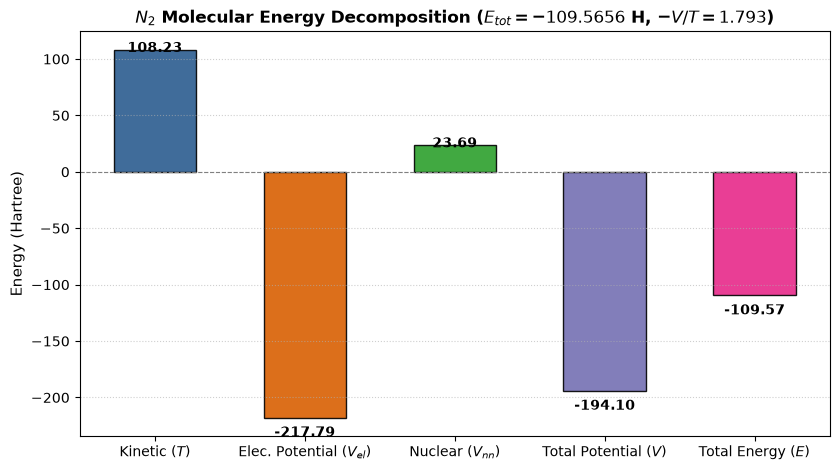

In [7]:
ke = json_data["kinetic_energy"]
pe = json_data["potential_energy"]
nuc = json_data["nuclear_repulsion"]
tot = json_data["total_energy"]
v_total = pe + nuc
virial_ratio = -v_total / ke

print(f"Kinetic Energy (T):          {ke:16.8f} Hartree")
print(f"Electronic Potential (V_el): {pe:16.8f} Hartree")
print(f"Nuclear Repulsion (V_nn):    {nuc:16.8f} Hartree")
print(f"Total Potential (V_tot):     {v_total:16.8f} Hartree")
print(f"Total Energy (E):            {tot:16.8f} Hartree")
print(f"Virial Ratio (-V_tot / T):   {virial_ratio:16.8f}  (Theoretical ~ 2.0)")

# Energy components bar chart
fig, ax = plt.subplots(figsize=(8.5, 4.8))
components = ['Kinetic ($T$)', 'Elec. Potential ($V_{el}$)', 'Nuclear ($V_{nn}$)', 'Total Potential ($V$)', 'Total Energy ($E$)']
values = [ke, pe, nuc, v_total, tot]
colors = ['#2b5c8f', '#d95f02', '#2ca02c', '#7570b3', '#e7298a']

bars = ax.bar(components, values, color=colors, width=0.55, edgecolor='black', alpha=0.9)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_ylabel("Energy (Hartree)", fontsize=11)
ax.set_title(f"$N_2$ Molecular Energy Decomposition ($E_{{tot}} = {tot:.4f}$ H, $-V/T = {virial_ratio:.3f}$)", fontsize=12, fontweight='bold')
ax.grid(axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    offset = 6 if height >= 0 else -16
    ax.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, offset),
                textcoords="offset points",
                ha='center', va='bottom' if height < 0 else 'top',
                fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Step 6: Molecular Orbital Spectrum & Occupations
The JSON output contains the orbital eigenvalues (`eigenvalues`) and fractional or integer occupations (`occupations`) across spin channels.
Below we tabulate the orbitals and plot the molecular orbital energy level diagram with HOMO/LUMO tags.

Number of Orbitals (NORBT): 10
Spin Channels:              2

Orbital Index | Alpha Energy (H) | Alpha Occ | Beta Energy (H)  | Beta Occ | State
--------------+------------------+-----------+------------------+----------+---------
   MO  1      |      -15.490043  |    1.00   |      -15.447665  |    1.00  | Occupied
   MO  2      |       -1.569620  |    1.00   |       -1.541878  |    0.99  | Occupied
   MO  3      |       -0.616765  |    0.96   |        0.125694  |    0.38  | Occupied
   MO  4      |       -0.116492  |    0.62   |        0.125694  |    0.38  | Occupied
   MO  5      |       -0.116492  |    0.62   |        0.194709  |    0.04  | Occupied
   MO  6      |      -15.447665  |    1.00   |      -15.490043  |    1.00  | Occupied
   MO  7      |       -1.541878  |    0.99   |       -1.569620  |    1.00  | Occupied
   MO  8      |        0.125694  |    0.38   |       -0.616765  |    0.96  | Virtual
   MO  9      |        0.125694  |    0.38   |       -0.116492  |    0.62  | Virtu

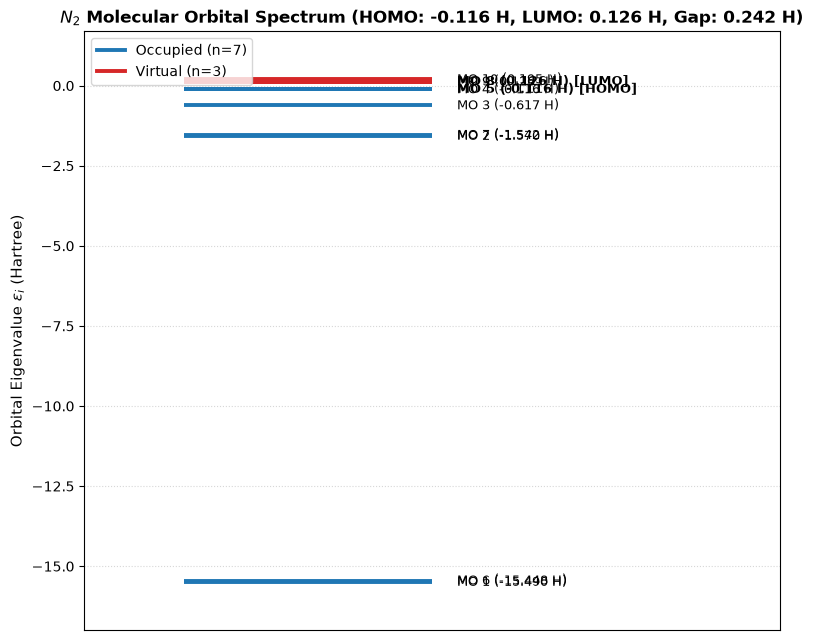

In [8]:
eigenvals = np.array(json_data["eigenvalues"])  # Shape: (norbt, ispin)
occupations = np.array(json_data["occupations"]) # Shape: (norbt, ispin)
norbt = json_data["norbt"]
ispin = json_data["ispin"]

print(f"Number of Orbitals (NORBT): {norbt}")
print(f"Spin Channels:              {ispin}")
print("\nOrbital Index | Alpha Energy (H) | Alpha Occ | Beta Energy (H)  | Beta Occ | State")
print("--------------+------------------+-----------+------------------+----------+---------")
for i in range(norbt):
    e_a = eigenvals[i, 0]
    o_a = occupations[i, 0]
    e_b = eigenvals[i, 1] if ispin > 1 else e_a
    o_b = occupations[i, 1] if ispin > 1 else o_a
    state_desc = "Occupied" if o_a > 0.5 else "Virtual"
    print(f"   MO {i+1:2d}      |    {e_a:12.6f}  |   {o_a:5.2f}   |    {e_b:12.6f}  |   {o_b:5.2f}  | {state_desc}")

# Molecular Orbital Diagram
fig, ax = plt.subplots(figsize=(8, 6.5))

alpha_energies = eigenvals[:, 0]
alpha_occs = occupations[:, 0]

occ_energies = [e for e, o in zip(alpha_energies, alpha_occs) if o > 0.5]
virt_energies = [e for e, o in zip(alpha_energies, alpha_occs) if o <= 0.5]
homo = max(occ_energies) if occ_energies else None
lumo = min(virt_energies) if virt_energies else None

for idx, (ene, occ) in enumerate(zip(alpha_energies, alpha_occs)):
    is_occ = occ > 0.5
    color = '#1f77b4' if is_occ else '#d62728'
    ax.hlines(ene, xmin=0.2, xmax=0.7, colors=color, linewidth=2.8)
    label = f"MO {idx+1} ({ene:.3f} H)"
    if ene == homo:
        label += " [HOMO]"
    elif ene == lumo:
        label += " [LUMO]"
    ax.text(0.75, ene, label, va='center', fontsize=9.5, fontweight='bold' if (ene==homo or ene==lumo) else 'normal')

ax.plot([], [], color='#1f77b4', linewidth=2.8, label=f'Occupied (n={len(occ_energies)})')
ax.plot([], [], color='#d62728', linewidth=2.8, label=f'Virtual (n={len(virt_energies)})')

ax.set_xlim(0.0, 1.4)
ax.set_ylim(min(alpha_energies) - 1.5, max(alpha_energies) + 1.5)
ax.set_xticks([])
ax.set_ylabel(r"Orbital Eigenvalue $\epsilon_i$ (Hartree)", fontsize=11)
title = "$N_2$ Molecular Orbital Spectrum"
if homo is not None and lumo is not None:
    gap = lumo - homo
    title += f" (HOMO: {homo:.3f} H, LUMO: {lumo:.3f} H, Gap: {gap:.3f} H)"
ax.set_title(title, fontsize=12, fontweight='bold')
ax.legend(loc='upper left', frameon=True)
ax.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## Step 7: Overlap Matrix ($S$) Reconstruction
In the Fortran core, symmetric matrices (such as overlap $S$ and Hamiltonian $H$) are stored in packed lower-triangular format of size $N(N+1)/2$ to minimize memory footprint.
Using `phatpsy.unpack_symmetric`, we expand the packed 1D array into the full $N \times N$ symmetric matrix and visualize it as a heatmap.

Packed array length:     55 (= 10*(10+1)/2)
Reconstructed S shape:   (10, 10)
Diagonal values (S_ii):  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Max off-diagonal:        0.8183


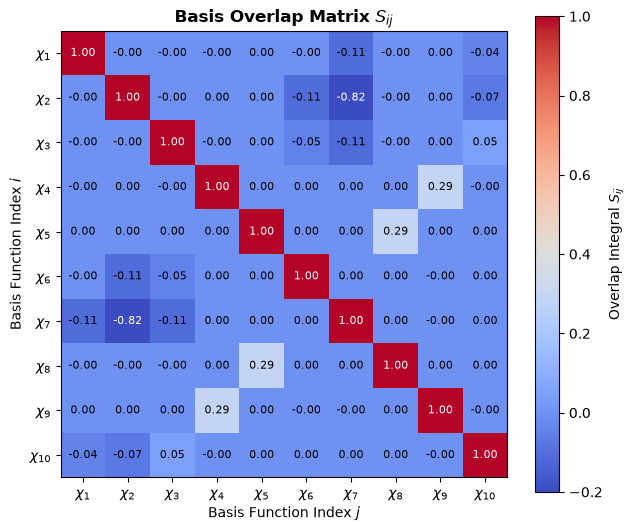

In [9]:
packed_overlap = np.array(json_data["overlap_packed"])
s_packed_a = packed_overlap[:, 0]
s_matrix = unpack_symmetric(s_packed_a, norbt)

print(f"Packed array length:     {len(s_packed_a)} (= {norbt}*({norbt}+1)/2)")
print(f"Reconstructed S shape:   {s_matrix.shape}")
print(f"Diagonal values (S_ii):  {np.round(np.diag(s_matrix), 4)}")
print(f"Max off-diagonal:        {np.max(np.abs(s_matrix - np.eye(norbt))):.4f}")

# Overlap Matrix Heatmap
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cax = ax.imshow(s_matrix, cmap='coolwarm', vmin=-0.2, vmax=1.0)
ax.set_title("Basis Overlap Matrix $S_{ij}$", fontsize=12, fontweight='bold')
ax.set_xlabel("Basis Function Index $j$", fontsize=10)
ax.set_ylabel("Basis Function Index $i$", fontsize=10)
ax.set_xticks(range(norbt))
ax.set_yticks(range(norbt))
ax.set_xticklabels([rf"$\chi_{{{k+1}}}$" for k in range(norbt)])
ax.set_yticklabels([rf"$\chi_{{{k+1}}}$" for k in range(norbt)])

for i in range(norbt):
    for j in range(norbt):
        val = s_matrix[i, j]
        text_color = "white" if abs(val) > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=8)

fig.colorbar(cax, ax=ax, label="Overlap Integral $S_{ij}$")
plt.tight_layout()
plt.show()

## Step 8: Molecular Orbital Coefficients Matrix ($C$)
The molecular orbital coefficients $C_{\mu i}$ define each canonical molecular orbital $\psi_i$ as a linear combination of atomic basis functions $\chi_\mu$:
$$\psi_i = \sum_{\mu} C_{\mu i} \chi_\mu$$
The coefficient matrix has dimensions $(M_{stot} \times N_{orbt})$. Below we visualize the Alpha orbital coefficient matrix.

MO Coefficient Matrix shape: (10, 10) (MSTOT=10 x NORBT=10)


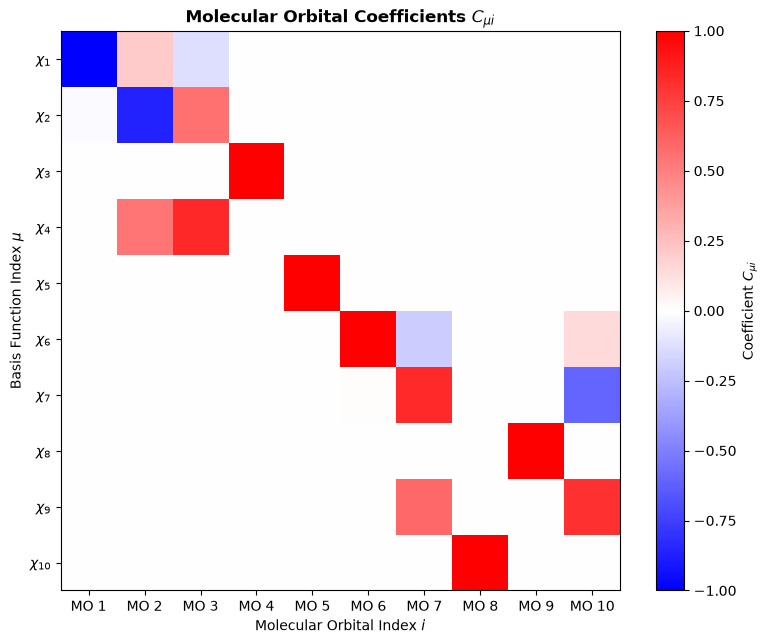

In [10]:
mo_coeffs = np.array(json_data["mo_coefficients"])
c_alpha = mo_coeffs[:, :, 0]

print(f"MO Coefficient Matrix shape: {c_alpha.shape} (MSTOT={c_alpha.shape[0]} x NORBT={c_alpha.shape[1]})")

fig, ax = plt.subplots(figsize=(8, 6.5))
vmax = np.max(np.abs(c_alpha))
cax = ax.imshow(c_alpha, cmap='bwr', vmin=-vmax, vmax=vmax)
ax.set_title(r"Molecular Orbital Coefficients $C_{\mu i}$", fontsize=12, fontweight='bold')
ax.set_xlabel("Molecular Orbital Index $i$", fontsize=10)
ax.set_ylabel(r"Basis Function Index $\mu$", fontsize=10)
ax.set_xticks(range(norbt))
ax.set_yticks(range(c_alpha.shape[0]))
ax.set_xticklabels([f"MO {k+1}" for k in range(norbt)])
ax.set_yticklabels([rf"$\chi_{{{k+1}}}$" for k in range(c_alpha.shape[0])])

fig.colorbar(cax, ax=ax, label=r"Coefficient $C_{\mu i}$")
plt.tight_layout()
plt.show()

## Step 9: Alternating-Spin Localized Valence-Bond (LVB) Representation

A hallmark of PHATPSY is its use of **spin-flipping (`QFLIP=T`)** to create an **alternating-spin Perfect-Pairing Valence-Bond (PP-VB / LVB)** representation—even for nominally "closed-shell" molecules!

### Why Localized Valence-Bond?
* In standard **Restricted Hartree-Fock (RHF)**, pairs of electrons are forced into identical spatial orbitals ($\phi_i(1)\phi_i(2)$), which overestimates unphysical ionic configurations ($A^- \dots B^+$) and fails to dissociate correctly.
* In PHATPSY's **Localized Valence-Bond** approach, electron pairs are decoupled into localized atomic channels:
  - Center 1 is $\alpha$-dominant (`spin="up"`, $+S_z$, Cyan halo)
  - Center 2 is $\beta$-dominant (`spin="down"`, $-S_z$, Orange halo, `QFLIP=T`)
  - The total molecular spin is strictly zero ($S_{z,\text{tot}} = 0.0000$), but the local pairing directly captures intra-bond electron correlation!

### Automated Alternating-Spin Assignment
The `phatpsy.spin` module analyzes molecular connectivity graphs and automatically assigns alternating `up` and `down` states. Because standard chemical `.xyz` formats specify coordinates in Ångströms, we pass `units="angstrom"` so bond lengths are properly converted into atomic units (Bohr) for connectivity analysis. Let's demonstrate this on an ethylene ($C_2H_4$) molecule:


In [11]:
# Build ethylene with automated alternating-spin assignment
# Note: Standard XYZ geometries are in Ångströms, so we pass units="angstrom"
xyz_c2h4 = '''6
Ethylene molecule (Ångström coordinates)
C  0.000000  0.000000  0.669500
C  0.000000  0.000000 -0.669500
H  0.000000  0.928900  1.232100
H  0.000000 -0.928900  1.232100
H  0.000000  0.928900 -1.232100
H  0.000000 -0.928900 -1.232100
'''

c2h4_deck = build_molecule(xyz_c2h4, basis="SZ", units="angstrom", auto_spin_flip=True)

print("--- Automated Alternating-Spin Assignment for Ethylene ---")
for idx, a in enumerate(c2h4_deck.geometry, 1):
    direction = "Alpha-dominant (UP)" if a.spin == "up" else "Beta-dominant (DOWN)"
    print(f"  Atom {idx:2d} ({a.element:<2s}): {direction:24s} at z={a.xyz[2]:8.4f} Bohr")

print("\nCompiled &ATOM cards showing automatic QFLIP=T emission:")
for line in c2h4_deck.to_stdin_text().splitlines():
    if "&ATOM" in line:
        print(" ", line)


--- Automated Alternating-Spin Assignment for Ethylene ---
  Atom  1 (C ): Alpha-dominant (UP)      at z=  1.2652 Bohr
  Atom  2 (C ): Beta-dominant (DOWN)     at z= -1.2652 Bohr
  Atom  3 (H ): Beta-dominant (DOWN)     at z=  2.3283 Bohr
  Atom  4 (H ): Beta-dominant (DOWN)     at z=  2.3283 Bohr
  Atom  5 (H ): Alpha-dominant (UP)      at z= -2.3283 Bohr
  Atom  6 (H ): Alpha-dominant (UP)      at z= -2.3283 Bohr

Compiled &ATOM cards showing automatic QFLIP=T emission:
   &ATOM XYZ=0.00000,0.00000,1.26517 &END
   &ATOM XYZ=0.00000,0.00000,-1.26517, QFLIP=T &END
   &ATOM XYZ=0.00000,1.75537,2.32833, QFLIP=T &END
   &ATOM XYZ=0.00000,-1.75537,2.32833, QFLIP=T &END
   &ATOM XYZ=0.00000,1.75537,-2.32833 &END
   &ATOM XYZ=0.00000,-1.75537,-2.32833 &END


## Step 10: Special Centers (Virtual Atoms, Fixed Atoms, and Symmetry)

PHATPSY natively supports three powerful atomic configuration flags:
1. **Virtual (Ghost) Atoms (`virtual=True`, `QVIRTL=T`)**: Centers that retain basis functions and external potentials but carry **no occupied electrons**. Used to complete the local coordination neighborhood and external potentials during local atomic calculations (excluded at the molecular EWMO level).
2. **Fixed (Frozen) Atoms (`fixed=True`, `QFIXED=T`)**: Atoms whose orbitals and local model potentials are frozen throughout SCF iterations. Used for QM/MM-style solvent scaffolds or frozen cores.
3. **Point-Group Symmetry (`SymmetrySpec`)**:
   - `ISYM = -1`: Reflection ($\sigma$) across the plane perpendicular to `IXYZ`
   - `ISYM = -2`: Inversion ($i$) through the origin
   - `ISYM = N`: $N$-fold rotation ($C_n$) about axis `IXYZ`

Below, we construct a custom system showcasing all three features:

In [12]:
# Nitrogen dimer with a fixed center, a virtual ghost probe, and symmetry reflection
special_atoms = [
    # Primary active Nitrogen atom
    AtomConfig(element="N", xyz=[0.0, 0.0, 1.034], spin="up"),
    
    # Symmetry-equivalent Nitrogen atom (reflected across xy-plane, spin-flipped)
    AtomConfig(
        element="N",
        symmetry=SymmetrySpec(ixyz=1, isym=-1, qflip=True),
        spin="down"
    ),
    
    # Virtual ghost basis center (e.g. for local coordination neighborhood completion)
    AtomConfig(element="H", xyz=[0.0, 2.0, 0.0], virtual=True),
    
    # Fixed / frozen environment atom
    AtomConfig(element="C", xyz=[0.0, -3.0, 0.0], fixed=True, spin="up"),
]

special_deck = CalculationDeck(
    title="Special Features Demonstration Deck",
    geometry=special_atoms,
    control=ControlConfig(spin_unrestricted=True),
)

print("--- Generated Special Features Input Deck ---")
print(special_deck.to_yaml())

--- Generated Special Features Input Deck ---
title: Special Features Demonstration Deck
control:
  spin_unrestricted: true
  max_cycles: 100
  convergence: 0.0001
  time_limit: 360.0
  charge_damp: 0.5
  charge_accel: 1.0
  potential_damp: 0.5
  potential_accel: 1.0
  pk_scale: 0.0
  separate_atoms_first_cycle: true
  debug: false
  trace: false
geometry:
- element: N
  xyz:
  - 0.0
  - 0.0
  - 1.034
  spin: up
- element: N
  xyz:
  - 0.0
  - 0.0
  - 0.0
  symmetry_op: -1
  symmetry_axis: 1
  spin: down
- element: H
  xyz:
  - 0.0
  - 2.0
  - 0.0
  virtual: true
- element: C
  xyz:
  - 0.0
  - -3.0
  - 0.0
  fixed: true
  spin: up



## Step 11: Interactive 3D WebGL Visualization in Jupyter

PHATPSY includes an embedded **3D Three.js WebGL visualizer** accessible directly from Python via `deck.show()`.

### Visual Color-Coding:
- **Spin Up ($\alpha$)**: Solid sphere with an upward cyan vector arrow ($\uparrow$)
- **Spin Down ($\beta$)**: Solid sphere with a downward orange vector arrow ($\downarrow$)
- **Virtual (Ghost) Centers**: Translucent wireframe spheres
- **Fixed (Frozen) Atoms**: Metallic gray wireframe bounding cages
- **Symmetry Elements**: Translucent reflection mirror planes (`ISYM=-1`), rotation axes (`ISYM=N`), and dashed links to generator atoms

Rotate, pan, and zoom the interactive 3D model below!

In [13]:
# Render interactive 3D WebGL widget inline in Jupyter
# You can rotate (left click), pan (right click), zoom (scroll), and toggle features!
special_deck.show()

In [14]:
# View Ethylene with Localized Valence-Bond alternating spin halos & glow
c2h4_deck.show()


### Standalone HTML Export & CLI Viewer
You can also export any calculation to a self-contained HTML file or launch the 3D viewer from the command line:

```python
# Export standalone HTML
special_deck.visualize(output_path="special_deck_3d.html", auto_open=False)
```

Or from your terminal:
```bash
# View any calculation deck or legacy stdin in 3D:
phatpsy view examples/ag13.stdin
phatpsy view examples/CO_ni_100.stdin

# Build an XYZ file with automatic alternating spin and view:
phatpsy view molecule.xyz --auto-spin
```


## Step 12: Calculation State Checkpointing & Warm Geometry Restarts

PHATPSY 2.0 provides full state serialization (`CalculationState`) supporting both structured JSON and compressed NumPy archive (`.npz`) checkpoints.

This enables:
1. **Auditability**: Complete persistence of all convergent wavefunctions, eigenvalues, density matrices, and energy breakdowns.
2. **Warm Restarts**: Re-using self-consistent field densities or eigenvectors to seed calculations with slightly perturbed atomic geometries (e.g., along a reaction pathway or PES scan).

In [15]:
from phatpsy.state import CalculationState

# Save converged calculation state from Step 2 to JSON checkpoint
state_json_path = REPO_ROOT / "data" / "n2_state_checkpoint.json"
results.save(state_json_path)
print(f"Calculation state checkpointed to: {state_json_path.relative_to(REPO_ROOT)}")

# Load state back from disk
loaded_state = CalculationState.load(state_json_path)
print(f"Loaded State Converged: {loaded_state.converged}")
print(f"Total Energy:           {loaded_state.total_energy:.8f} Hartree")
print(f"Virial Theorem (-V/T):  {loaded_state.virial_ratio:.6f}")
print(f"Number of Orbitals:     {loaded_state.norbt}")

# Create a warm restart deck for a slightly perturbed geometry (e.g. R = 2.10 Bohr)
restart_deck = loaded_state.create_restart_deck(
    new_geometry=[("N", 0.0, 0.0, 1.05), ("N", 0.0, 0.0, -1.05)],
    title="N2 Warm Restart (R = 2.10 Bohr)"
)
print("\nGenerated warm-restart deck with converged starting orbitals from checkpoint:")
print(f"Atoms in restart deck: {len(restart_deck.atoms)}")
print(f"Starting orbitals per atom: {len(restart_deck.atoms[0].starting_orbitals)}")

Calculation state checkpointed to: data/n2_state_checkpoint.json
Loaded State Converged: True
Total Energy:           -109.56561386 Hartree
Virial Theorem (-V/T):  2.012351
Number of Orbitals:     10

Generated warm-restart deck with converged starting orbitals from checkpoint:
Atoms in restart deck: 2
Starting orbitals per atom: 5


## Step 13: Transferable Embedded Atomic States

In the Projected Hamiltonian methodology, polyatomic calculations partition the electronic structure into **localized atomic states** embedded in the molecular environment. 

Each atom accumulates an effective localized charge distribution, spin polarization, and local model potential. PHATPSY allows extracting an `EmbeddedAtomState` and transferring it to other systems (e.g., fixed substrate atoms in a chemisorption cluster):

In [16]:
from phatpsy.state import EmbeddedAtomState

# Extract the embedded atom state for the first nitrogen center
n_atom = results.get_embedded_atom(0)

print(f"Embedded Atom ID:     {n_atom.atom_id or 'Atom #1'}")
print(f"Element:              {n_atom.element} (Z = {n_atom.atomic_number})")
print(f"Nuclear Charge:       {n_atom.nuclear_charge:.4f}")
print(f"Electronic Charge:    {n_atom.electronic_charge:.4f}")
print(f"Net Charge:           {n_atom.net_charge:+.4f}")
print(f"Alpha / Beta Spin:    {n_atom.alpha_spin:.4f} / {n_atom.beta_spin:.4f}")
print(f"Net Spin (S_z):       {n_atom.net_spin:.4f}")
print(f"Basis Functions:      {len(n_atom.basis_functions)}")
print(f"Converged Orbitals:   {len(n_atom.orbitals)}")

# Save transferable embedded atom state
n_atom_path = REPO_ROOT / "data" / "n_atom_embedded.json"
n_atom.save(n_atom_path)
print(f"\nTransferable embedded atomic state saved to: {n_atom_path.relative_to(REPO_ROOT)}")

Embedded Atom ID:     Atom #1
Element:              N (Z = 7)
Nuclear Charge:       7.0000
Electronic Charge:    7.0000
Net Charge:           +0.0000
Alpha / Beta Spin:    4.2097 / 2.7903
Net Spin (S_z):       1.4195
Basis Functions:      5
Converged Orbitals:   5

Transferable embedded atomic state saved to: data/n_atom_embedded.json


## Step 14: Internal Coordinates, Wilson B-Matrix & Z-Matrix Transformations

Modern quantum chemical workflows operate naturally in internal curvilinear coordinates (bond lengths, valence angles, and dihedral torsions) rather than redundant Cartesians.

The [`phatpsy.coords`](file:///Users/jacksmith/phatpsy2/phatpsy/coords.py) module provides:
1. **Automatic Internal Coordinates Detection** (`InternalCoordinates.from_atoms`):
   - Determines chemical connectivity using atomic covalent radii.
   - Identifies all bond distances $R(i, j)$, valence angles $\theta(i, j, k)$, and proper dihedrals $\phi(i, j, k, l)$.
2. **Wilson B-Matrix Evaluation** (`InternalCoordinates.b_matrix`):
   - Computes analytical transformation gradients relating internal coordinate changes to Cartesian displacements:
     $$B_{ki} = \frac{\partial q_k}{\partial x_i}, \quad \Delta \mathbf{q} \approx \mathbf{B} \,\Delta \mathbf{x}$$
   - Satisfies exact translational and rotational invariance: $\sum_i \mathbf{s}_i = 0$ and $\sum_i \mathbf{r}_i \times \mathbf{s}_i = 0$.
3. **Canonical Z-Matrix & NeRF Reconstruction** (`ZMatrix`):
   - Constructs standard internal coordinate Z-matrices from Cartesian geometries.
   - Reconstructs 3D Cartesian coordinates via the Natural Extension Reference Frame (NeRF) algorithm with exact metric fidelity ($< 10^{-15}$ interatomic distortion).

In [21]:
# Automatic Internal Coordinates and Wilson B-Matrix on Ethylene (C2H4)
from phatpsy.coords import InternalCoordinates, ZMatrix

xyz_c2h4 = '''6
Ethylene molecule (Ångström coordinates)
C  0.000000  0.000000  0.669500
C  0.000000  0.000000 -0.669500
H  0.000000  0.928900  1.232100
H  0.000000 -0.928900  1.232100
H  0.000000  0.928900 -1.232100
H  0.000000 -0.928900 -1.232100
'''
c2h4_deck = build_molecule(xyz_c2h4, basis="SZ", units="angstrom")
atoms = c2h4_deck.atoms
coords = np.array([a.xyz for a in atoms])

# 1. Automatically detect internal coordinates
ic = InternalCoordinates.from_atoms(atoms)
print(f"Detected {ic.num_coordinates} internal coordinates for Ethylene:")
print(f"  Bonds ({len(ic.bonds)}):      {[b.name for b in ic.bonds]}")
print(f"  Angles ({len(ic.angles)}):     {[a.name for a in ic.angles]}")
print(f"  Dihedrals ({len(ic.dihedrals)}):  {[d.name for d in ic.dihedrals]}")

# 2. Calculate values and Wilson B-matrix
q_vals = ic.calculate(coords, angles_in_degrees=True)
B = ic.b_matrix(coords)
print(f"\nWilson B-matrix shape: {B.shape} (N_internal x 3*N_atoms)")
print(f"  Bond R(C1-C2):   {q_vals[0]:.4f} Bohr")
print(f"  Angle A(C2-C1-H3): {q_vals[5]:.2f} degrees")

# 3. Canonical Z-Matrix and NeRF Cartesian Reconstruction
zm = ZMatrix.from_atoms(atoms)
recon_coords = zm.to_cartesian()

# Verify exact preservation of all pairwise interatomic distances
max_distortion = max(
    abs(np.linalg.norm(coords[i] - coords[j]) - np.linalg.norm(recon_coords[i] - recon_coords[j]))
    for i in range(len(atoms)) for j in range(i + 1, len(atoms))
)
print(f"\nZ-Matrix NeRF Reconstruction Check:")
print(f"  Entries generated: {len(zm.entries)}")
print(f"  Max pairwise distance distortion: {max_distortion:.2e} Bohr (exact metric preservation)")


Detected 15 internal coordinates for Ethylene:
  Bonds (5):      ['R(C1-C2)', 'R(C1-H3)', 'R(C1-H4)', 'R(C2-H5)', 'R(C2-H6)']
  Angles (6):     ['A(C2-C1-H3)', 'A(C2-C1-H4)', 'A(H3-C1-H4)', 'A(C1-C2-H5)', 'A(C1-C2-H6)', 'A(H5-C2-H6)']
  Dihedrals (4):  ['D(H3-C1-C2-H5)', 'D(H3-C1-C2-H6)', 'D(H4-C1-C2-H5)', 'D(H4-C1-C2-H6)']

Wilson B-matrix shape: (15, 18) (N_internal x 3*N_atoms)
  Bond R(C1-C2):   2.5303 Bohr
  Angle A(C2-C1-H3): 121.73 degrees

Z-Matrix NeRF Reconstruction Check:
  Entries generated: 6
  Max pairwise distance distortion: 8.88e-16 Bohr (exact metric preservation)


## Step 15: Automated 1D & 2D Potential Energy Surface (PES) Mapping

The [`phatpsy.pes`](file:///Users/jacksmith/phatpsy2/phatpsy/pes.py) module automates Potential Energy Surface (PES) mapping with built-in state warm-restarts across geometry points:
- `scan_1d`: Automated 1D coordinate scans (bonds or valence angles), tracking total energies, virial ratios ($-V/T$), and quadratic parabolic equilibrium estimation.
- `scan_2d`: Automated 2D grid scans producing filled contour energy maps with minimum location markers.
- `.save_json()`: Complete data export of PES points, convergence flags, and energies.
- `.plot()`: Instant visualization of energy profiles, virial ratio boundary invariants, and 2D contour surfaces.

1D PES Scan Results for Bond R(N1-N2):
  Discrete Minimum:   R = 1.400 Bohr (E = -110.767105 Ha)
  Parabolic Fit Min:  R_e = 1.400 Bohr

  Distance (Bohr) | Energy (Hartree) | Virial (-V/T) | Converged
  ----------------+------------------+---------------+----------
       1.250      |      -110.325662   |     2.0225    |   True
       1.300      |      -110.621402   |     2.0253    |   True
       1.350      |      -110.748524   |     2.0261    |   True
       1.400      |      -110.767105   |     2.0262    |   True
       1.450      |      -110.725535   |     2.0257    |   True
       1.500      |      -110.642538   |     2.0248    |   True
       1.600      |      -110.410368   |     2.0220    |   True
       1.700      |      -110.126467   |     2.0191    |   True
       1.800      |      -109.825620   |     2.0159    |   True

Saved PES dataset to /Users/jacksmith/phatpsy2/data/n2_pes_scan.json


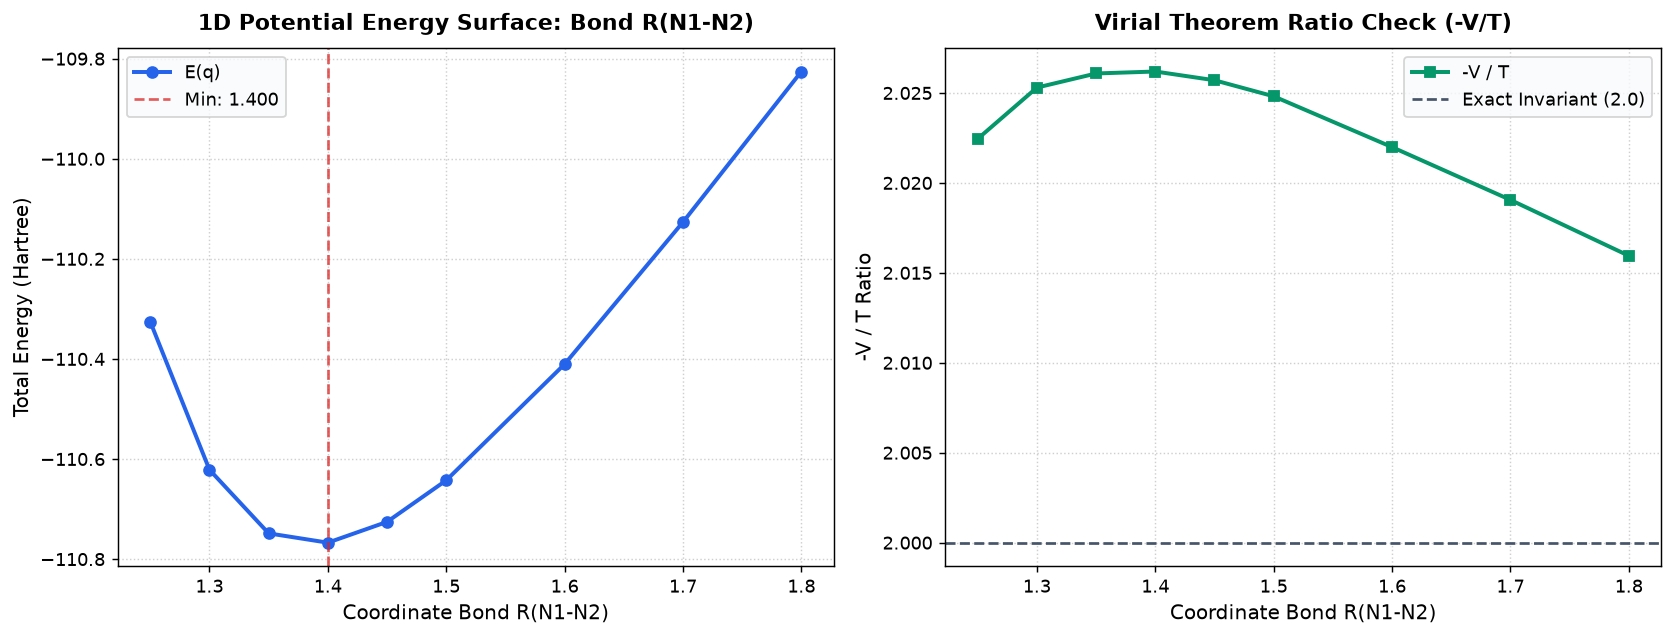

In [22]:
# Automated 1D Potential Energy Surface (PES) Scan on N2
from phatpsy.pes import scan_1d, scan_2d
from phatpsy.io import parse_stdin_to_deck

n2_deck = parse_stdin_to_deck(REPO_ROOT / "examples" / "n2.stdin")

# Perform automated 1D scan with warm wavefunction restarts
scan_points = [1.25, 1.30, 1.35, 1.40, 1.45, 1.50, 1.60, 1.70, 1.80]
res_1d = scan_1d(n2_deck, ("bond", 0, 1), scan_points, warm_restart=True)

print(f"1D PES Scan Results for {res_1d.coordinate_name}:")
print(f"  Discrete Minimum:   R = {res_1d.min_value:.3f} Bohr (E = {res_1d.min_energy:.6f} Ha)")
print(f"  Parabolic Fit Min:  R_e = {res_1d.equilibrium_value:.3f} Bohr")
print("\n  Distance (Bohr) | Energy (Hartree) | Virial (-V/T) | Converged")
print("  ----------------+------------------+---------------+----------")
for v, e, vr, c in zip(res_1d.values, res_1d.energies, res_1d.virial_ratios, res_1d.converged):
    print(f"      {v:6.3f}      |   {e:14.6f}   |    {vr:7.4f}    |   {c}")

# Save structured JSON data and plot dual-panel PES profile
pes_json_path = REPO_ROOT / "data" / "n2_pes_scan.json"
res_1d.save_json(pes_json_path)
print(f"\nSaved PES dataset to {pes_json_path}")

res_1d.plot();


2D PES Surface Minimum: (1.3, 1.4) -> E = -111.028245 Hartree


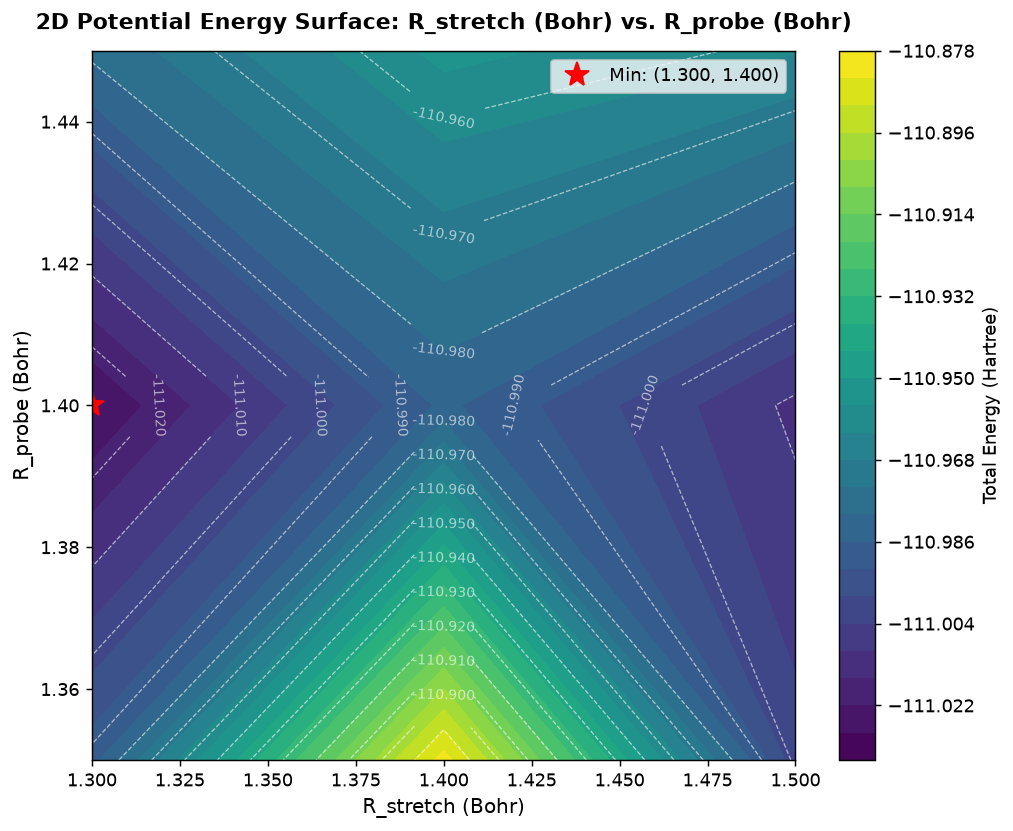

In [23]:
# Automated 2D Grid Potential Energy Surface (PES) Scan
grid1 = [1.30, 1.40, 1.50]
grid2 = [1.35, 1.40, 1.45]

res_2d = scan_2d(
    n2_deck,
    ("bond", 0, 1), grid1,
    ("bond", 0, 1), grid2,
    coord1_name="R_stretch (Bohr)",
    coord2_name="R_probe (Bohr)",
    warm_restart=True,
)

print(f"2D PES Surface Minimum: {res_2d.min_values} -> E = {res_2d.min_energy:.6f} Hartree")
res_2d.plot();


## Step 16: Ground-State Geometry Optimization via BFGS Relaxation

The [`phatpsy.optimize`](file:///Users/jacksmith/phatpsy2/phatpsy/optimize.py) module performs autonomous ground-state structure relaxation to locate local energy minima.

Key algorithmic components:
1. **BFGS Quasi-Newton Updates**: Recursively approximates the inverse Hessian $H_{k+1}$ from displacement $\mathbf{s}_k$ and gradient difference $\mathbf{y}_k$.
2. **Trust-Region Step Limit Clamping**: Restricts the maximum step size $\|\mathbf{p}\| \le \delta_{\max}$ (default: $0.15\ \text{Bohr}$) to prevent wild excursions.
3. **Armijo Backtracking Line Search**: Ensures sufficient energy decrease at each iteration ($E(x + \alpha p) \le E(x) + c_1 \alpha \mathbf{g}^T \mathbf{p}$).
4. **Active Center Constraints**: Respects frozen atoms (`fixed=True`), ghost centers (`virtual=True`), and symmetry-generated coordinates.
5. **State Seeding**: Accelerates finite-difference gradients and consecutive optimization steps using warm wavefunction restarts.

Initial Displaced Bond Length: 2.150 Bohr
Optimization Converged:
  Iterations:     7
  Initial Energy:      -109.387905 Hartree
  Final Energy:        -110.769956 Hartree
  Energy Delta:          -1.382052 Hartree (Monotonic Decrease!)

Trajectory History:
  Step | Energy (Hartree) | ||grad E|| (Ha/Bohr) | Virial (-V/T)
  -----+------------------+---------------------+--------------
     0 |      -109.387905   |         5.58338     |     2.0106
     1 |      -109.627289   |         6.26994     |     2.0131
     2 |      -110.042158   |         5.80777     |     2.0182
     3 |      -110.722274   |         2.75375     |     2.0246
     4 |      -110.766029   |         0.93876     |     2.0252
     5 |      -110.768864   |         0.44848     |     2.0252
     6 |      -110.769948   |         0.03409     |     2.0252
     7 |      -110.769956   |         0.00173     |     2.0252

Relaxed Cartesian Geometry (Bohr):
  Atom 1 (N): [  0.2669,   0.1651,   0.6996]
  Atom 2 (N): [  0.0000,   0

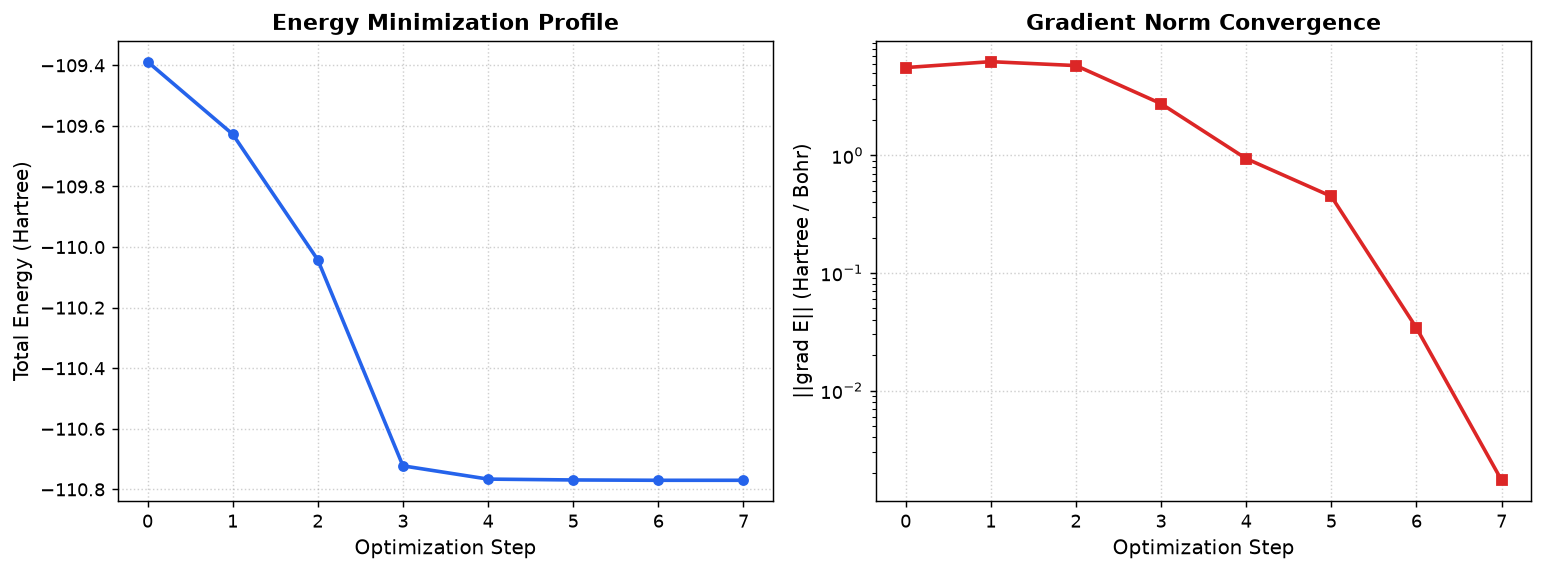

In [24]:
# BFGS Ground-State Geometry Optimization on Stretched N2
from phatpsy.optimize import optimize_geometry
from phatpsy.pes import modify_deck_geometry

# Start from a stretched bond length (R = 2.15 Bohr)
stretched_deck = modify_deck_geometry(n2_deck, "bond", (0, 1), 2.15)
print(f"Initial Displaced Bond Length: {2.15:.3f} Bohr")

# Execute BFGS relaxation
opt_res = optimize_geometry(
    stretched_deck,
    max_steps=8,
    grad_tol=1e-3,
    energy_tol=1e-5,
    warm_restart=True,
)

print(f"Optimization {'Converged' if opt_res.converged else 'Completed'}:")
print(f"  Iterations:     {opt_res.num_steps}")
print(f"  Initial Energy: {opt_res.initial_energy:16.6f} Hartree")
print(f"  Final Energy:   {opt_res.final_energy:16.6f} Hartree")
print(f"  Energy Delta:   {opt_res.energy_change:16.6f} Hartree (Monotonic Decrease!)")

print("\nTrajectory History:")
print("  Step | Energy (Hartree) | ||grad E|| (Ha/Bohr) | Virial (-V/T)")
print("  -----+------------------+---------------------+--------------")
for s in opt_res.trajectory:
    print(f"    {s.step:2d} |   {s.energy:14.6f}   |      {s.grad_norm:10.5f}     |    {s.virial_ratio:7.4f}")

# Display relaxed atomic coordinates
print("\nRelaxed Cartesian Geometry (Bohr):")
for idx, a in enumerate(opt_res.optimized_deck.atoms, 1):
    print(f"  Atom {idx} ({a.element}): [{a.xyz[0]:8.4f}, {a.xyz[1]:8.4f}, {a.xyz[2]:8.4f}]")

# Plot convergence history
opt_res.plot_convergence();


## Step 17: Direct Access to Pure Modern Fortran 2018 Kernels (`_phatpsy_core`)

With all 7 modernization groups completed, the Fortran engine in `src/` is now **100% pure Fortran 2018 (`.f90`)** with zero legacy `.f` files.

Every scientific kernel is directly exposed to Python via typed modules:
- `core.linalg`: High-performance LAPACK solvers, similarity transforms (`cdct`, `ctsc`, `pcct`), block insertions (`insert`, `insrtd`), and orthonormalization (`schmid`, `normlz`).
- `core.density`: One-electron density matrix generator (`denmat`), Löwdin/Mulliken population analysis (`chrgbo`, `mulpop`), and expectation value integrals (`averag`).
- `core.modelpot`: Analytical spherical harmonic normalization, factorials, and model potential damping (`dampv`).
- `core.symmetry`: Euler rotation matrices (`genrot`) and symmetry projections (`sympak`, `sympro`).
- `core.diagnostics`: Periodic table noble core counts (`noble`) and coordinate grid projections (`mapndx`).

In [25]:
# Direct calls to modernized Fortran 2018 modules
print("Testing direct calls to Fortran 2018 kernels via _phatpsy_core:")

# 1. Diagnostics: Noble gas core orbital counts across the periodic table
print(f"  core.diagnostics.noble(Z=1  [H]):  {core.diagnostics.noble(1)} core orbitals")
print(f"  core.diagnostics.noble(Z=7  [N]):  {core.diagnostics.noble(7)} core orbitals")
print(f"  core.diagnostics.noble(Z=18 [Ar]): {core.diagnostics.noble(18)} core orbitals")
print(f"  core.diagnostics.noble(Z=47 [Ag]): {core.diagnostics.noble(47)} core orbitals")

# 2. Symmetry: Analytical 3D Euler rotation matrix
rot = core.symmetry.genrot(alpha=0.0, beta=np.pi/4, gamma=0.0)
print(f"\n  core.symmetry.genrot (45 deg Y-rotation):\n{np.round(rot, 4)}")

# 3. Density: One-electron density matrix construction D = C * occ * C^T
c_test = np.eye(3, 2, order='F', dtype=np.float64)
occ_test = np.array([2.0, 1.0], dtype=np.float64)
dens_packed = core.density.denmat(c_test, occ_test)
print(f"\n  core.density.denmat (diagonal 2, 1 packed):\n  {dens_packed}")

Testing direct calls to Fortran 2018 kernels via _phatpsy_core:
  core.diagnostics.noble(Z=1  [H]):  0 core orbitals
  core.diagnostics.noble(Z=7  [N]):  1 core orbitals
  core.diagnostics.noble(Z=18 [Ar]): 5 core orbitals
  core.diagnostics.noble(Z=47 [Ag]): 18 core orbitals

  core.symmetry.genrot (45 deg Y-rotation):
[[ 0.7071  0.      0.7071]
 [ 0.      1.      0.    ]
 [-0.7071  0.      0.7071]]

  core.density.denmat (diagonal 2, 1 packed):
  [2. 0. 1. 0. 0. 0.]


## Step 18: Periodic Crystal Supercells & Surface Slab Generator

PHATPSY 2.0 includes a comprehensive crystal and surface slab generator (`phatpsy.supercell`) designed to bridge periodic crystallography with molecular surface chemisorption:
- **3D Crystal Lattices (`Lattice`)**: Arbitrary metric tensors, cubic, tetragonal, orthorhombic, and hexagonal systems, direct/reciprocal lattice vectors, and fractional $\leftrightarrow$ Cartesian coordinate conversion.
- **Bulk Supercell Replication (`PeriodicCell`)**: Standard bulk element crystals (FCC, BCC, Diamond) with automatic bipartite antiferromagnetic spin ordering.
- **Oriented Surface Slabs (`build_slab`)**: High-index facets ((100), (111), (110)), customizable atomic layers, vacuum buffers, substrate layer freezing (`QFIXED=T`), and perimeter virtual ghost atoms (`QVIRTL=T`).
- **Surface Adsorbate Placement (`attach_adsorbate`)**: Direct mounting of molecules ($CO$, $NO$, $H_2$, etc.) onto high-symmetry surface sites (`top`, `bridge`, `hollow`) with specified height and tilt angles.
- **Multi-Format Interoperability**: Export to POSCAR (VASP), CIF (crystallography), XYZ, and PHATPSY `CalculationDeck` (.yaml, .json, .stdin).

In [ ]:
import numpy as np
from phatpsy.supercell import Lattice, PeriodicCell

# 1. Construct bulk FCC Nickel conventional unit cell (a = 3.524 A)
bulk_ni = PeriodicCell.bulk("Ni", crystal_structure="fcc")
print(f"Bulk Ni Unit Cell: {bulk_ni.formula}, Volume = {bulk_ni.lattice.volume:.3f} Bohr^3")
print(f"  Lattice a: {bulk_ni.lattice.a:.3f} Bohr ({bulk_ni.lattice.a / 1.889726:.3f} Angstrom)")

# 2. Replicate into 2x2x2 supercell with bipartite alternating spin
ni_supercell = bulk_ni.build_supercell((2, 2, 2), auto_spin=True)
print(f"2x2x2 Supercell: {len(ni_supercell.atoms)} atoms ({ni_supercell.formula})")
up = sum(1 for a in ni_supercell.atoms if a.spin == "up")
down = sum(1 for a in ni_supercell.atoms if a.spin == "down")
print(f"  Spin Balance: {up} alpha (up) / {down} beta (down)")

# 3. Reciprocal lattice vectors (b1, b2, b3)
recip = ni_supercell.lattice.reciprocal_lattice
print(f"Reciprocal Lattice Norms |b_i|: {recip.a:.4f}, {recip.b:.4f}, {recip.c:.4f} Bohr^-1")

# 4. Preview POSCAR export
print("\n--- POSCAR Header Preview ---")
print("\n".join(ni_supercell.to_poscar().strip().split("\n")[:8]))

In [ ]:
from phatpsy.supercell import build_slab, attach_adsorbate
from phatpsy.visualizer import show_deck

# 1. Build Ni(100) 3-layer slab with 15 A vacuum and 2x2 in-plane supercell
# Freeze bottom layer (fixed_layers=1)
slab = build_slab(
    element="Ni",
    miller_index=(1, 0, 0),
    layers=3,
    vacuum=15.0,
    repeat=(2, 2),
    fixed_layers=1,
)
print(f"Built Ni(100) Slab: {len(slab.atoms)} substrate atoms")
print(f"  Fixed Substrate Atoms (QFIXED=T): {sum(1 for a in slab.atoms if a.fixed)}")
print(f"  Top Surface Atoms with LVB Spin:  {sum(1 for a in slab.atoms if a.layer == 3)}")

# 2. Attach CO adsorbate to on-top site (h = 1.90 A above surface Ni atom)
slab_with_co = attach_adsorbate(
    slab,
    adsorbate="CO",
    site_type="top",
    height=1.90,
)
print(f"Attached CO: Total atoms = {len(slab_with_co.atoms)}")

# 3. Print atomic layout table
print(f"\n{'Idx':<4} {'Elem':<5} {'X (Bohr)':<10} {'Y (Bohr)':<10} {'Z (Bohr)':<10} {'Fixed':<7} {'Spin':<6} {'Tag'}")
print("-" * 65)
for i, a in enumerate(slab_with_co.atoms, 1):
    fixed_str = "YES" if a.fixed else "no"
    spin_str = a.spin or "none"
    print(f"{i:<4d} {a.element:<5} {a.cart_coords[0]:<10.4f} {a.cart_coords[1]:<10.4f} {a.cart_coords[2]:<10.4f} {fixed_str:<7} {spin_str:<6} {a.tag or ''}")

# 4. Convert to PHATPSY CalculationDeck and render interactive 3D WebGL viewer
slab_deck = slab_with_co.to_deck(basis="SZ", title="CO on Ni(100) Surface Slab")
show_deck(slab_deck, height=520)


## Summary & Architectural Milestones

The modernized **PHATPSY 2.0** package unites modern scientific computing with clean high-performance Fortran:
- **100% Pure Fortran 2018 Core**: All 109 legacy routines modernized into modern free-form modules with zero `.f` files remaining in `src/`.
- **Full In-Memory Storage & LAPACK**: Scratch disk tapes completely eliminated; linear algebra upgraded to industry-standard LAPACK.
- **Localized Valence-Bond (LVB) Theory**: Native support for alternating-spin perfect-pairing, virtual ghost centers, and point-group symmetry.
- **Transferable Embedded Atoms & Checkpointing**: Calculations can be serialized to JSON/NPZ, warm-restarted across geometries, and individual embedded atom states transferred between calculations.
- **Internal Coordinates & Wilson B-Matrix**: Exact torque-conserving analytical Wilson B-matrices and canonical Z-matrix NeRF Cartesian reconstruction.
- **Automated 1D & 2D Potential Energy Surface (PES) Mapping**: High-throughput rigid and relaxed PES curve and 2D contour surface scanning with warm wavefunction acceleration.
- **BFGS Structure Relaxation & Geometry Optimization**: Autonomous gradient-based ground-state minimization with trust-region step clamping and Armijo line search.
- **Interactive 3D WebGL Visualization**: Integrated Three.js 3D rendering and trajectory visualization directly in Jupyter.